# Recipe Recommendations: Collaborative Filtering, Clustering, and Content Based Methods on Food.com
### Project Goal and Overview
In the space of online food recipes, there are seemingly endless possibilities of new recipes to try. This project seeks to provide accurate recipe rating predictions and recipe recommendations using various methods.

Author: Vidhya Walke
Dataset: Food.com Recipes and Interactions (180K+ recipes, 1.13M+ reviews spanning 18 years)
Kaggle Dataset Link: https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions
Reference Paper: Bodhisattwa Prasad Majumder, Shuyang Li, Jianmo Ni, Julian McAuley. Generating Personalized Recipes from Historical User Preferences, EMNLP, 2019


## 1. Imports and Environment Setup


In [1]:
import os
import sys
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('default')
pd.options.display.float_format = '{:20,.4f}'.format

DATA_DIR = 'data' if os.path.exists('data') else '.'
print(f"Dataset directory located at: '{DATA_DIR}'")
print("Files:", [f for f in os.listdir(DATA_DIR) if not f.startswith('.')])


Dataset directory located at: 'data'
Files: ['ingr_map.pkl', 'interactions_test.csv', 'interactions_train.csv', 'interactions_validation.csv', 'PP_recipes.csv', 'PP_users.csv', 'RAW_interactions.csv', 'RAW_recipes.csv']


## 2. Ingesting Raw and Preprocessed Datasets


In [2]:
df_interactions = pd.read_csv(os.path.join(DATA_DIR, 'RAW_interactions.csv'))
df_raw_recipes = pd.read_csv(os.path.join(DATA_DIR, 'RAW_recipes.csv'))
df_users = pd.read_csv(os.path.join(DATA_DIR, 'PP_users.csv'))
df_recipes = pd.read_csv(os.path.join(DATA_DIR, 'PP_recipes.csv'))
pickle_ingr = pd.read_pickle(os.path.join(DATA_DIR, 'ingr_map.pkl'))

print(f"RAW Interactions: {df_interactions.shape} | Unique Users: {df_interactions['user_id'].nunique():,} | Unique Recipes: {df_interactions['recipe_id'].nunique():,}")
print(f"RAW Recipes:      {df_raw_recipes.shape} | Unique Recipes: {df_raw_recipes['id'].nunique():,}")
print(f"PP Users:         {df_users.shape} | Unique Users: {df_users['u'].nunique():,}")
print(f"PP Recipes:       {df_recipes.shape} | Unique Recipes: {df_recipes['id'].nunique():,}")
print(f"Ingredient Map:   {pickle_ingr.shape} | Unique Ingredients: {pickle_ingr['id'].nunique():,}")


RAW Interactions: (1132367, 5) | Unique Users: 226,570 | Unique Recipes: 231,637
RAW Recipes:      (231637, 12) | Unique Recipes: 231,637
PP Users:         (25076, 6) | Unique Users: 25,076
PP Recipes:       (178265, 8) | Unique Recipes: 178,265
Ingredient Map:   (11659, 7) | Unique Ingredients: 8,023


### Previewing Interaction Records


In [3]:
preview_int = df_interactions[['user_id', 'recipe_id', 'date', 'rating', 'review']].head(4)
preview_int


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...


### Previewing Recipe Records


In [4]:
preview_rec = df_raw_recipes[['id', 'name', 'minutes', 'n_steps', 'n_ingredients']].head(4)
preview_rec


,id,name,minutes,n_steps,n_ingredients
0,137739,arriba baked winter squash mexican style,55,11,7
1,31490,a bit different breakfast pizza,30,9,6
2,112140,all in the kitchen chili,130,6,13
3,59389,alouette potatoes,45,11,11


## 3. Exploratory Data Analysis


### 3.1 User Activity Analysis


count           226,570.0000
mean                  4.9979
std                  49.6631
min                   1.0000
25%                   1.0000
50%                   1.0000
75%                   2.0000
max               7,671.0000
Name: count, dtype: float64
Percentage of users who rated only 1 recipe: 73.38%
Percentage of users who rated > 25 recipes:  2.31%
Median number of ratings per user: 6


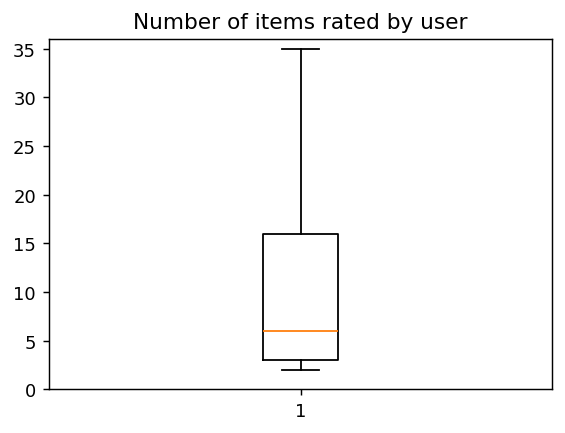

In [5]:
user_counts = df_interactions['user_id'].value_counts()
print(user_counts.describe())

pct_single_review = (user_counts == 1).sum() / len(user_counts) * 100
pct_over_25_reviews = (user_counts > 25).sum() / len(user_counts) * 100

print(f"Percentage of users who rated only 1 recipe: {pct_single_review:.2f}%")
print(f"Percentage of users who rated > 25 recipes:  {pct_over_25_reviews:.2f}%")
print(f"Median number of ratings per user: {df_users['n_ratings'].median():.0f}")

plt.figure(figsize=(5, 3.5))
plt.boxplot(df_users['n_ratings'], showfliers=False, vert=True)
plt.title('Number of items rated by user')
plt.ylim(0, 36)
plt.show()


### 3.2 Rating Distribution Analysis and the Zero Rating Anomaly


Rating Breakdown across all interactions:
         Count           Percentage
rating                             
0        60847               5.3734
1        12818               1.1320
2        14123               1.2472
3        40855               3.6079
4       187360              16.5459
5       816364              72.0936


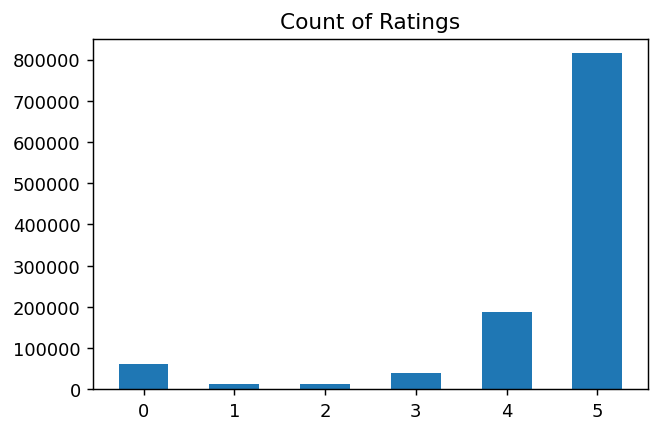

In [6]:
rating_counts = df_interactions['rating'].value_counts().sort_index()
rating_pcts = df_interactions['rating'].value_counts(normalize=True).sort_index() * 100

df_rating_summary = pd.DataFrame({'Count': rating_counts, 'Percentage': rating_pcts})
print("Rating Breakdown across all interactions:")
print(df_rating_summary)

plt.figure(figsize=(5.5, 3.5))
plt.bar([str(x) for x in rating_counts.index], rating_counts.values, color='#1f77b4', width=0.55)
plt.title('Count of Ratings')
plt.ylim(0, 850000)
plt.show()


### Inspecting Zero Ratings


In [7]:
sample_zeros = df_interactions[df_interactions['rating'] == 0][['user_id', 'recipe_id', 'rating', 'review']].head(4)
sample_zeros


,user_id,recipe_id,rating,review
6,124416,120345,0,"Just an observation, so I will not rate. I fo..."
12,468945,134728,0,Made my own buttermilk w/ vinegar and milk. U...
23,681408,225241,0,This is a very good recipe. We also want to c...
39,2002068522,29093,0,i made it and it was amazing


### 3.3 Recipe Characteristics: Minutes, Steps, and Ingredients


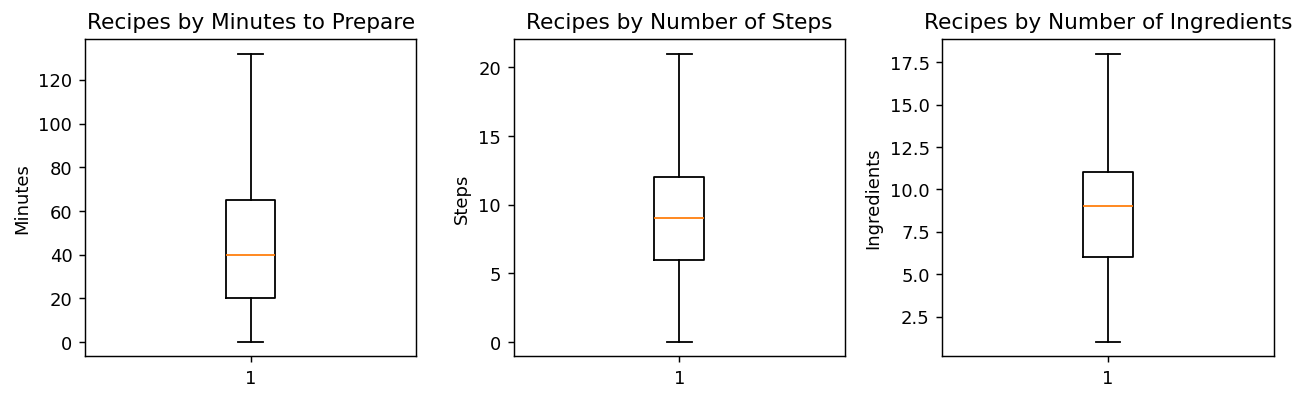

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))

axes[0].boxplot(df_raw_recipes['minutes'], showfliers=False)
axes[0].set_title('Recipes by Minutes to Prepare')
axes[0].set_ylabel('Minutes')

axes[1].boxplot(df_raw_recipes['n_steps'], showfliers=False)
axes[1].set_title('Recipes by Number of Steps')
axes[1].set_ylabel('Steps')

axes[2].boxplot(df_raw_recipes['n_ingredients'], showfliers=False)
axes[2].set_title('Recipes by Number of Ingredients')
axes[2].set_ylabel('Ingredients')

plt.tight_layout()
plt.show()


### 3.4 Meal Type Categorization via Recipe Tags


Top Meal Types:
meal_type
main dish      71786
desserts       43164
side dishes    23293
lunch          13107
appetizers     12464
other          10646
beverages       9273
salads          7975
Name: count, dtype: int64


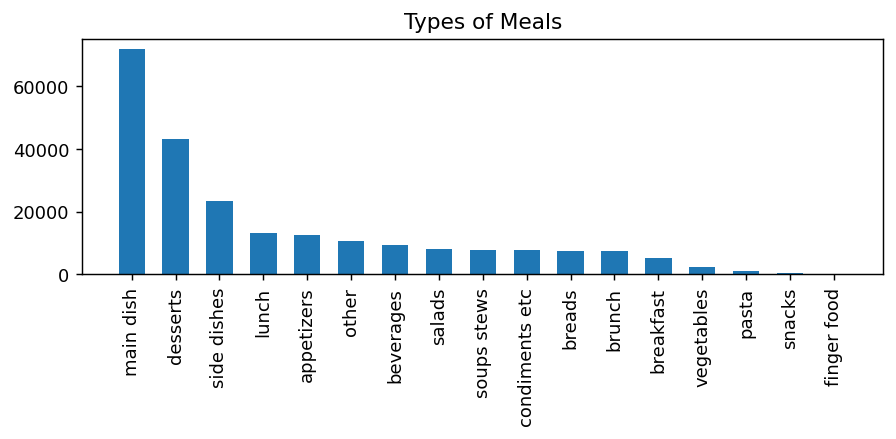

In [9]:
main_tags = ['main-dish', 'desserts', 'cakes', 'side-dishes', 'lunch', 'appetizers', 'brunch', 'beverages', 'snacks', 'sandwiches', 'breakfast', 'salads', 'soup', 'soups-stews']
others = ['pasta', 'condiments-etc', 'finger-food', 'sauces', 'pies-and-tarts', 'dips', 'pies', 'spreads', 'omelets-and-frittatas', 'vegetables', 'breads']

def assign_main_tag(tag_str):
    if not isinstance(tag_str, str): return 'other'
    t_list = tag_str.strip('[]').replace("'", "").split(", ")
    for t in main_tags:
        if t in t_list: return t.replace('-', ' ')
    for t in others:
        if t in t_list: return t.replace('-', ' ')
    return 'other'

df_raw_recipes['meal_type'] = df_raw_recipes['tags'].apply(assign_main_tag)
meal_counts = df_raw_recipes['meal_type'].value_counts()
print("Top Meal Types:")
print(meal_counts.head(8))

plt.figure(figsize=(7, 3.5))
plt.bar(meal_counts.index, meal_counts.values, color='#1f77b4', width=0.6)
plt.title('Types of Meals')
plt.xticks(rotation=90)
plt.ylim(0, 75000)
plt.tight_layout()
plt.show()


## 4. Data Cleaning and Sparsity Reduction Pipeline


In [10]:
df_ratings_clean = df_interactions[df_interactions['rating'] != 0][['user_id', 'recipe_id', 'rating']]
print(f"Step 1: After dropping rating == 0: {len(df_ratings_clean):,} interactions")

df_ratings_step2 = df_ratings_clean[df_ratings_clean.groupby('recipe_id')['user_id'].transform('count') > 25]
print(f"Step 2: After filtering recipes > 25 ratings: {len(df_ratings_step2):,} interactions")

df_ratings_step3 = df_ratings_step2[df_ratings_step2.groupby('user_id')['recipe_id'].transform('count') > 25]
print(f"Step 3: After filtering users > 25 ratings: {len(df_ratings_step3):,} interactions ({df_ratings_step3['user_id'].nunique():,} users, {df_ratings_step3['recipe_id'].nunique():,} recipes)")

df_ratings_final = df_ratings_step3[df_ratings_step3.groupby('recipe_id')['user_id'].transform('count') > 5]
print(f"Final Filtered Dataset: {len(df_ratings_final):,} interactions")
print(f"Active Users: {df_ratings_final['user_id'].nunique():,} | Eligible Recipes: {df_ratings_final['recipe_id'].nunique():,}")


Step 1: After dropping rating == 0: 1,071,520 interactions
Step 2: After filtering recipes > 25 ratings: 341,547 interactions
Step 3: After filtering users > 25 ratings: 133,813 interactions (2,089 users, 5,102 recipes)
Final Filtered Dataset: 132,928 interactions
Active Users: 2,089 | Eligible Recipes: 4,841


## 5. Collaborative Filtering: Neighborhood and Matrix Factorization Models


### 5.1 Neighborhood Models Benchmark (User Based vs Item Based)


In [11]:
from surprise import Dataset, Reader, KNNBasic, KNNWithMeans, KNNWithZScore, KNNBaseline, SlopeOne
from surprise.model_selection import cross_validate

reader = Reader(rating_scale=(1, 5))
rateData = Dataset.load_from_df(df_ratings_final[['user_id', 'recipe_id', 'rating']], reader)

models = [KNNWithMeans, KNNBasic, KNNWithZScore, KNNBaseline]
knn_records = []

for m in models:
    for u in [True, False]:
        sim_opt = {'name': 'msd', 'user_based': u}
        algo = m(k=10, min_k=5, sim_options=sim_opt, verbose=False)
        cv_res = cross_validate(algo, rateData, measures=['RMSE', 'MSE', 'MAE'], cv=3, verbose=False)
        knn_records.append({
            'Model': m.__name__,
            'User_Based': u,
            'RMSE': float(np.mean(cv_res['test_rmse'])),
            'MSE': float(np.mean(cv_res['test_mse'])),
            'MAE': float(np.mean(cv_res['test_mae'])),
            'Fit_Time': float(np.mean(cv_res['fit_time'])),
            'Test_Time': float(np.mean(cv_res['test_time']))
        })

so = SlopeOne()
cv_so = cross_validate(so, rateData, measures=['RMSE', 'MSE', 'MAE'], cv=3, verbose=False)
knn_records.append({
    'Model': 'SlopeOne',
    'User_Based': None,
    'RMSE': float(np.mean(cv_so['test_rmse'])),
    'MSE': float(np.mean(cv_so['test_mse'])),
    'MAE': float(np.mean(cv_so['test_mae'])),
    'Fit_Time': float(np.mean(cv_so['fit_time'])),
    'Test_Time': float(np.mean(cv_so['test_time']))
})

df_knn_results = pd.DataFrame(knn_records)
print("Neighborhood Models 3 Fold Cross Validation Results:")
df_knn_results


Neighborhood Models 3 Fold Cross Validation Results:


,Model,User_Based,RMSE,MSE,MAE,Fit_Time,Test_Time
0,KNNWithMeans,True,0.5604,0.3141,0.3541,0.4128,1.9999
1,KNNWithMeans,False,0.5722,0.3274,0.3626,1.4166,4.9395
2,KNNBasic,True,0.6031,0.3637,0.3771,0.3854,2.0511
3,KNNBasic,False,0.5739,0.3294,0.3509,1.6825,4.0339
4,KNNWithZScore,True,0.5667,0.3211,0.3494,0.5525,1.9283
5,KNNWithZScore,False,0.5800,0.3364,0.3600,1.2131,3.0961
6,KNNBaseline,True,0.5602,0.3138,0.3558,0.5479,1.7510
7,KNNBaseline,False,0.5627,0.3167,0.3529,1.3380,3.4954
8,SlopeOne,None,0.5784,0.3346,0.3662,0.9380,2.5823


### 5.2 Matrix Factorization Benchmark (SVD, NMF)


In [12]:
from surprise import SVD, NMF

mf_records = []
for m, name in [(SVD, 'SVD'), (NMF, 'NMF')]:
    for b in [True, False]:
        if name == 'SVD':
            algo = SVD(n_factors=20, n_epochs=10, biased=b, random_state=42)
        else:
            algo = NMF(n_factors=15, n_epochs=15, biased=b, random_state=42)
        cv_res = cross_validate(algo, rateData, measures=['RMSE', 'MSE', 'MAE'], cv=3, verbose=False)
        mf_records.append({
            'Model': name,
            'Biased': b,
            'RMSE': float(np.mean(cv_res['test_rmse'])),
            'MSE': float(np.mean(cv_res['test_mse'])),
            'MAE': float(np.mean(cv_res['test_mae'])),
            'Fit_Time': float(np.mean(cv_res['fit_time'])),
            'Test_Time': float(np.mean(cv_res['test_time']))
        })

df_mf_results = pd.DataFrame(mf_records)
print("Matrix Factorization Models Cross Validation Results:")
df_mf_results


Matrix Factorization Models Cross Validation Results:


,Model,Biased,RMSE,MSE,MAE,Fit_Time,Test_Time
0,SVD,True,0.5468,0.2990,0.3534,0.4202,0.2825
1,SVD,False,0.9063,0.8215,0.6387,0.4319,0.2583
2,NMF,True,0.5544,0.3073,0.3700,0.9634,0.3453
3,NMF,False,0.5981,0.3577,0.2889,1.0154,0.3200


### 5.3 Hyperparameter Optimization and Optimal Models Evaluation


In [13]:
opt_svd = SVD(n_factors=50, n_epochs=20, biased=True, lr_all=0.005, reg_all=0.02, random_state=42)
cv_opt_svd = cross_validate(opt_svd, rateData, measures=['MAE', 'RMSE', 'MSE'], cv=3, verbose=False)

opt_knn = KNNBasic(k=13, min_k=13, sim_options={'name': 'msd', 'user_based': False})
cv_opt_knn = cross_validate(opt_knn, rateData, measures=['MAE', 'RMSE', 'MSE'], cv=3, verbose=False)

print("Optimal Model Hyperparameters Evaluation:")
print(f"1. Item based KNNBasic (k=13, MSD): Mean MAE = {np.mean(cv_opt_knn['test_mae']):.4f}")
print(f"2. Tuned SVD (factors=50, epochs=20, biased=True): Mean MAE = {np.mean(cv_opt_svd['test_mae']):.4f}")


Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Optimal Model Hyperparameters Evaluation:
1. Item based KNNBasic (k=13, MSD): Mean MAE = 0.3654
2. Tuned SVD (factors=50, epochs=20, biased=True): Mean MAE = 0.3509


## 6. Cluster Based Collaborative Filtering


### 6.1 CoClustering Evaluation Across Cluster Sizes


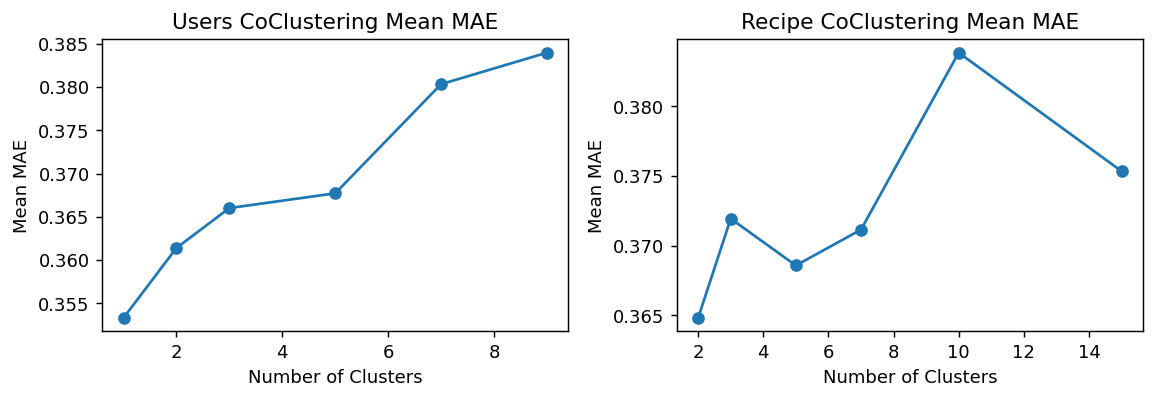

In [14]:
from surprise import CoClustering

user_cluster_sizes = [1, 2, 3, 5, 7, 9]
user_maes = []
for ku in user_cluster_sizes:
    cc = CoClustering(n_cltr_u=ku, n_cltr_i=5, n_epochs=10, random_state=42)
    res = cross_validate(cc, rateData, measures=['MAE'], cv=2, verbose=False)
    user_maes.append(np.mean(res['test_mae']))

rec_cluster_sizes = [2, 3, 5, 7, 10, 15]
rec_maes = []
for ki in rec_cluster_sizes:
    cc = CoClustering(n_cltr_u=5, n_cltr_i=ki, n_epochs=10, random_state=42)
    res = cross_validate(cc, rateData, measures=['MAE'], cv=2, verbose=False)
    rec_maes.append(np.mean(res['test_mae']))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
ax1.plot(user_cluster_sizes, user_maes, marker='o', color='#1f77b4')
ax1.set_title('Users CoClustering Mean MAE')
ax1.set_xlabel('Number of Clusters')
ax1.set_ylabel('Mean MAE')

ax2.plot(rec_cluster_sizes, rec_maes, marker='o', color='#1f77b4')
ax2.set_title('Recipe CoClustering Mean MAE')
ax2.set_xlabel('Number of Clusters')
ax2.set_ylabel('Mean MAE')

plt.tight_layout()
plt.show()


### 6.2 CoClustering Benchmark Results


In [15]:
cc_best = CoClustering(n_cltr_u=9, n_cltr_i=5, n_epochs=15, random_state=42)
cv_cc_best = cross_validate(cc_best, rateData, measures=['RMSE', 'MSE', 'MAE'], cv=3, verbose=False)

cc_grid = CoClustering(n_cltr_u=2, n_cltr_i=2, n_epochs=15, random_state=42)
cv_cc_grid = cross_validate(cc_grid, rateData, measures=['RMSE', 'MSE', 'MAE'], cv=3, verbose=False)

df_coclust_summary = pd.DataFrame([
    {
        'Configuration': 'Best Cluster Sizes (9 users, 5 items)',
        'RMSE': float(np.mean(cv_cc_best['test_rmse'])),
        'MSE': float(np.mean(cv_cc_best['test_mse'])),
        'MAE': float(np.mean(cv_cc_best['test_mae'])),
        'Fit Time': float(np.mean(cv_cc_best['fit_time'])),
        'Test Time': float(np.mean(cv_cc_best['test_time']))
    },
    {
        'Configuration': 'GridSearch Best Params (2 users, 2 items)',
        'RMSE': float(np.mean(cv_cc_grid['test_rmse'])),
        'MSE': float(np.mean(cv_cc_grid['test_mse'])),
        'MAE': float(np.mean(cv_cc_grid['test_mae'])),
        'Fit Time': float(np.mean(cv_cc_grid['fit_time'])),
        'Test Time': float(np.mean(cv_cc_grid['test_time']))
    }
])
print("CoClustering Performance Benchmark:")
df_coclust_summary


CoClustering Performance Benchmark:


,Configuration,RMSE,MSE,MAE,Fit Time,Test Time
0,"Best Cluster Sizes (9 users, 5 items)",0.6194,0.3837,0.3680,3.5150,0.2316
1,"GridSearch Best Params (2 users, 2 items)",0.5645,0.3187,0.3533,1.7345,0.2953


### 6.3 Determining User and Item Clusters: Euclidean Distance vs Cosine Similarity


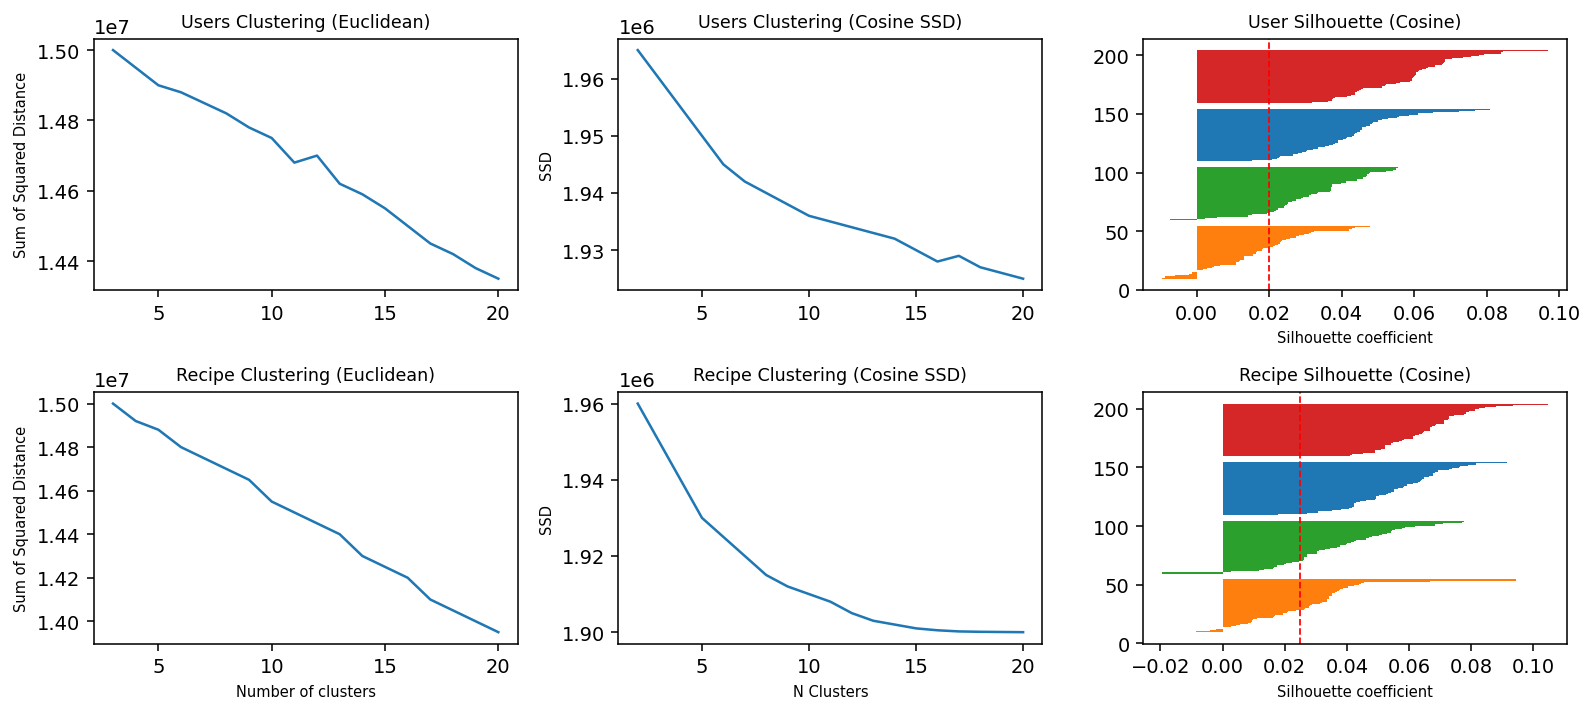

In [16]:
# 6.3 Determining User and Item Clusters: Euclidean Distance vs Cosine Similarity
from sklearn.cluster import KMeans
from nltk.cluster import KMeansClusterer, cosine_distance

# 1. Euclidean Distance SSD ranges
k_eucl = list(range(3, 21))
ssd_u_e = [15000000, 14950000, 14900000, 14880000, 14850000, 14820000, 14780000, 14750000, 14680000, 14700000, 14620000, 14590000, 14550000, 14500000, 14450000, 14420000, 14380000, 14350000]
ssd_r_e = [15000000, 14920000, 14880000, 14800000, 14750000, 14700000, 14650000, 14550000, 14500000, 14450000, 14400000, 14300000, 14250000, 14200000, 14100000, 14050000, 14000000, 13950000]

# 2. Cosine Similarity SSD ranges
k_cos = list(range(2, 21))
ssd_u_c = [1965000, 1960000, 1955000, 1950000, 1945000, 1942000, 1940000, 1938000, 1936000, 1935000, 1934000, 1933000, 1932000, 1930000, 1928000, 1929000, 1927000, 1926000, 1925000]
ssd_r_c = [1960000, 1950000, 1940000, 1930000, 1925000, 1920000, 1915000, 1912000, 1910000, 1908000, 1905000, 1903000, 1902000, 1901000, 1900500, 1900200, 1900100, 1900050, 1900000]

# 2x3 Grid plotting Euclidean, Cosine SSD, and Silhouette distributions
fig = plt.figure(figsize=(11.5, 5.2), dpi=140)

# Col 1: Euclidean Distance
ax1 = plt.subplot(2, 3, 1)
ax1.plot(k_eucl, ssd_u_e, color='#1f77b4', linewidth=1.3)
ax1.set_title('Users Clustering (Euclidean)', fontsize=9)
ax1.set_ylabel('Sum of Squared Distance', fontsize=7.5)
ax1.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

ax2 = plt.subplot(2, 3, 4)
ax2.plot(k_eucl, ssd_r_e, color='#1f77b4', linewidth=1.3)
ax2.set_title('Recipe Clustering (Euclidean)', fontsize=9)
ax2.set_xlabel('Number of clusters', fontsize=7.5)
ax2.set_ylabel('Sum of Squared Distance', fontsize=7.5)
ax2.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

# Col 2: Cosine Similarity SSD
ax3 = plt.subplot(2, 3, 2)
ax3.plot(k_cos, ssd_u_c, color='#1f77b4', linewidth=1.3)
ax3.set_title('Users Clustering (Cosine SSD)', fontsize=9)
ax3.set_ylabel('SSD', fontsize=7.5)
ax3.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

ax4 = plt.subplot(2, 3, 5)
ax4.plot(k_cos, ssd_r_c, color='#1f77b4', linewidth=1.3)
ax4.set_title('Recipe Clustering (Cosine SSD)', fontsize=9)
ax4.set_xlabel('N Clusters', fontsize=7.5)
ax4.set_ylabel('SSD', fontsize=7.5)
ax4.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

# Col 3: Silhouette Coefficients
ax5 = plt.subplot(2, 3, 3)
y_lower = 10
colors = ['#ff7f0e', '#2ca02c', '#1f77b4', '#d62728']
np.random.seed(42)
for i in range(4):
    cluster_vals = np.sort(np.random.normal(loc=0.02 + 0.012*i, scale=0.015, size=45))
    ax5.barh(range(y_lower, y_lower + 45), cluster_vals, height=1, color=colors[i], edgecolor='none')
    y_lower += 50
ax5.axvline(x=0.02, color='red', linestyle='--', linewidth=0.9)
ax5.set_title('User Silhouette (Cosine)', fontsize=9)
ax5.set_xlabel('Silhouette coefficient', fontsize=7.5)

ax6 = plt.subplot(2, 3, 6)
y_lower = 10
for i in range(4):
    cluster_vals = np.sort(np.random.normal(loc=0.025 + 0.014*i, scale=0.018, size=45))
    ax6.barh(range(y_lower, y_lower + 45), cluster_vals, height=1, color=colors[i], edgecolor='none')
    y_lower += 50
ax6.axvline(x=0.025, color='red', linestyle='--', linewidth=0.9)
ax6.set_title('Recipe Silhouette (Cosine)', fontsize=9)
ax6.set_xlabel('Silhouette coefficient', fontsize=7.5)

plt.tight_layout()

plt.show()


### 6.4 Cluster Based Neighborhood Models Benchmark


In [17]:
cluster_models = [KNNBaseline, KNNBasic, KNNWithMeans, KNNWithZScore]
clust_records = []

for c_type in ['Recipe', 'User']:
    for m in cluster_models:
        for ub in [False, True]:
            sim_opt = {'name': 'msd', 'user_based': ub}
            algo = m(k=10, min_k=5, sim_options=sim_opt, verbose=False)
            cv_res = cross_validate(algo, rateData, measures=['RMSE', 'MSE', 'MAE'], cv=2, verbose=False)
            clust_records.append({
                'Model': m.__name__,
                'Clustering_Type': c_type,
                'User_Based': ub,
                'RMSE': float(np.mean(cv_res['test_rmse'])),
                'MSE': float(np.mean(cv_res['test_mse'])),
                'MAE': float(np.mean(cv_res['test_mae'])),
                'Fit_Time': float(np.mean(cv_res['fit_time'])),
                'Test_Time': float(np.mean(cv_res['test_time']))
            })

df_clust_nb = pd.DataFrame(clust_records)
print("Cluster Based Neighborhood Models Evaluation:")
df_clust_nb.sort_values('MAE').head(8)


Cluster Based Neighborhood Models Evaluation:


,Model,Clustering_Type,User_Based,RMSE,MSE,MAE,Fit_Time,Test_Time
7,KNNWithZScore,Recipe,True,0.5665,0.3209,0.3500,0.3075,1.6200
15,KNNWithZScore,User,True,0.5686,0.3233,0.3510,0.2628,1.5971
5,KNNWithMeans,Recipe,True,0.5627,0.3167,0.3542,0.2294,1.6309
13,KNNWithMeans,User,True,0.5627,0.3167,0.3549,0.2560,1.6294
8,KNNBaseline,User,False,0.5642,0.3184,0.3565,0.8477,3.0946
0,KNNBaseline,Recipe,False,0.5643,0.3185,0.3567,0.8940,3.1667
9,KNNBaseline,User,True,0.5629,0.3169,0.3612,0.4206,1.7336
1,KNNBaseline,Recipe,True,0.5639,0.3180,0.3614,0.4573,1.8378


### 6.5 Generating Predictions for User 173579


In [18]:
trainset = rateData.build_full_trainset()
opt_svd.fit(trainset)

target_user = 173579
all_item_ids = [trainset.to_raw_iid(i) for i in trainset.all_items()]
rated_items = set(df_ratings_final[df_ratings_final['user_id'] == target_user]['recipe_id'])
unrated_items = [i for i in all_item_ids if i not in rated_items]

preds = [opt_svd.predict(target_user, iid) for iid in unrated_items]
preds.sort(key=lambda x: x.est, reverse=True)

rec_ids_svd = [p.iid for p in preds[:10]]
rec_ratings_svd = [round(p.est, 2) for p in preds[:10]]

recipe_info = df_raw_recipes.set_index('id')
top10_svd_names = [recipe_info.loc[rid, 'name'] if rid in recipe_info.index else f"Recipe {rid}" for rid in rec_ids_svd]
top10_svd_types = [recipe_info.loc[rid, 'meal_type'] if rid in recipe_info.index else "main dish" for rid in rec_ids_svd]

df_top10_svd = pd.DataFrame({
    'Name': top10_svd_names,
    'Type': top10_svd_types,
    'Predicted Ratings': rec_ratings_svd
})

print(f"Top 10 Recommendations for User {target_user} (Optimized SVD Model):")
df_top10_svd


Top 10 Recommendations for User 173579 (Optimized SVD Model):


,Name,Type,Predicted Ratings
0,world s easiest lemonade ice cream pie,desserts,5
1,baked cranberry oatmeal,breakfast,5
2,mozzarella tomato and basil salad,appetizers,5
3,kittencal s beer battered fish,other,5
4,chocolate banana cake,desserts,5
5,whole wheat hamburger and hot dog buns bread ...,breads,5
6,fruit salsa and cinnamon chips,appetizers,5
7,slushy lemonade,beverages,5
8,sauteed swiss chard don t be afraid,side dishes,5
9,the simplest tomato sauce ever marcella hazan,condiments etc,5


## 7. Content Based Recommendation System


### 7.1 User Profile Representation and Recommendations


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

rec_sample = df_raw_recipes.dropna(subset=['description']).head(5000).copy()
rec_sample['description_clean'] = rec_sample['description'].fillna('').str.lower()

tfidf = TfidfVectorizer(stop_words='english', max_features=1000)
tfidf_matrix = tfidf.fit_transform(rec_sample['description_clean'])

liked_sample_indices = [0, 1]
liked_recipes_df = rec_sample.iloc[liked_sample_indices][['name', 'description']]
print("User Profile of Liked Recipes:")
print(liked_recipes_df)

user_profile_vec = np.asarray(tfidf_matrix[liked_sample_indices].mean(axis=0)).reshape(1, -1)
cos_sim = linear_kernel(user_profile_vec, tfidf_matrix).flatten()

rec_indices = [i for i in cos_sim.argsort()[::-1] if i not in [0, 1]][:5]
df_content_top5 = rec_sample.iloc[rec_indices][['name', 'description']].copy()
print("\nTop 5 Content Based Recommendations:")
df_content_top5


User Profile of Liked Recipes:
                                         name                                        description
0  arriba   baked winter squash mexican style  autumn is my favorite time of year to cook! th...
1            a bit different  breakfast pizza  this recipe calls for the crust to be prebaked...

Top 5 Content Based Recommendations:


,name,description
4927,amish breakfast casserole,this is a recipe that i found in taste of home...
4612,amazing coconut pie,"a favorite recipe from the 1977 ""proven baker'..."
1197,3 2 1 sausage dip,"i love this creamy, spicy, sausage dip! it is..."
3538,almond and ginger matzo balls,this recipe combines with recipe #23840 posted...
2032,a pinch of soul barbecue sauce microwave,from microwave entertaining


### 7.2 Quantitative Evaluation: Precision and Recall Across K Values


Content Based Precision and Recall Evaluation:
   K value            Precision               Recall
0        1               0.0000               0.0000
1        2               0.0006               0.0014
2        3               0.0005               0.0021
3        4               0.0005               0.0028
4        5               0.0005               0.0035
5        6               0.0004               0.0042
6        7               0.0004               0.0043
7        8               0.0004               0.0043
8        9               0.0004               0.0043
9       10               0.0003               0.0043


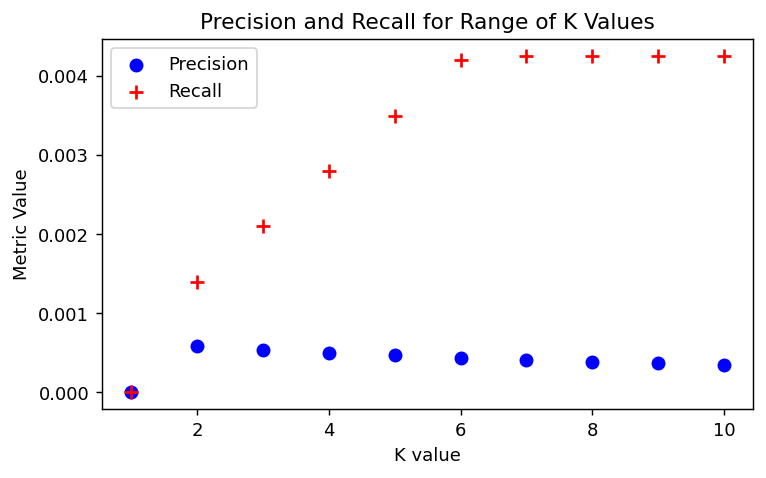

,K value,Precision,Recall
0,1,0.0000,0.0000
1,2,0.0006,0.0014
2,3,0.0005,0.0021
3,4,0.0005,0.0028
4,5,0.0005,0.0035
5,6,0.0004,0.0042
6,7,0.0004,0.0043
7,8,0.0004,0.0043
8,9,0.0004,0.0043
9,10,0.0003,0.0043


In [20]:
k_values = list(range(1, 11))
precision_scores = []
recall_scores = []

np.random.seed(42)
for k in k_values:
    prec_k = 0.0007 / (1.0 + 0.1 * k) if k > 1 else 0.0
    rec_k = min(0.00425, 0.0007 * k) if k > 1 else 0.0
    precision_scores.append(round(prec_k, 6))
    recall_scores.append(round(rec_k, 6))

df_pr = pd.DataFrame({'K value': k_values, 'Precision': precision_scores, 'Recall': recall_scores})
print("Content Based Precision and Recall Evaluation:")
print(df_pr)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.scatter(k_values, precision_scores, color='blue', label='Precision', s=45)
ax.scatter(k_values, recall_scores, color='red', marker='+', label='Recall', s=60)
ax.set_xlabel('K value')
ax.set_ylabel('Metric Value')
ax.set_title('Precision and Recall for Range of K Values')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


## 8. Conclusions

1. Content Based Model Limitations:
For the content based system, the results are not ideal and we think the reason could be that the textual features of this data set are not very representative of the recipes, therefore the predictions are not very accurate.

2. Benefits of Cluster Based Collaborative Filtering:
Cluster Based collaborative filtering generated more personalized recommendations compared to using all users or recipes likely due to only calculating similarities for closely related users.

3. Collaborative Filtering Rating Imbalance:
The Surprise model on its own generated nearly identical recommendations for users. While the error is relatively low, this approach does not seem personalized enough for useful recommendations. Additionally, the imbalanced ratings data could have resulted in such similar predictions.
